# Your own area: a cloud-filled Sentinel-2 mosaic of Columbus, Ohio

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/blob/main/notebooks/your_own_area_columbus.ipynb)

The [walkthrough notebook](sentinel2_walkthrough.ipynb) runs the pipeline on a
fixed demo area in Taiwan. This notebook shows how to run it on an area and
season of your own choice, here central Columbus, Ohio, in summer 2024. It uses
[geoai-datacubes](https://github.com/buckai-observatory/geoai-datacubes) to define the area, find the Sentinel-2 acquisitions,
and download them onto one common grid.

The notebook

1. defines an area of interest (AOI) of 20 km x 20 km around downtown Columbus;
2. lists every Sentinel-2 acquisition of that area from July to October 2024 and
   measures its cloud cover **inside the AOI**;
3. selects three partly cloudy acquisitions to mosaic and three clear ones to
   fill the clouds;
4. downloads them with geoai-datacubes and converts them to the pipeline's
   inputs;
5. runs Steps 2-4 and shows the result, with a before/after slider.

To use another area or season, change the values in sections 2 and 3 and run
the notebook again. Run the cells from top to bottom; on Colab this takes about
5 minutes and nothing has to be installed on your computer.

## 1. Setup

### 1.1 Install the pipeline and geoai-datacubes (Colab) or use this repository (local)

**What this cell does.** On Colab, it clones this repository to
`/content/cloud-mosaic`, installs the GDAL command-line tools and the pipeline's
Python packages (with OpenCV older than 4.11, which the pipeline needs; see the
walkthrough notebook) and installs `geoai-datacubes` from PyPI. This takes
about two minutes.

Run locally, the cell installs nothing: use the locked `notebook` environment
of this repository (`pixi run --locked -e notebook jupyter lab`), which
includes geoai-datacubes.

In [1]:
import pathlib
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/buckai-observatory/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline.git"
BRANCH = "main"

def sh(command):
    """Run a shell command and stop with its output if it fails."""
    result = subprocess.run(command, shell=True, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError(f"failed: {command}")

if IN_COLAB:
    REPO = pathlib.Path("/content/cloud-mosaic")
    if not REPO.exists():
        sh(f"git clone --depth 1 --branch {BRANCH} {REPO_URL} {REPO}")
    sh("apt-get -qq update && apt-get -qq install -y gdal-bin")
    sh("pip uninstall -y -q opencv-python opencv-python-headless opencv-contrib-python")
    sh(f"pip install -q -r {REPO}/requirements.txt geoai-datacubes")
else:
    REPO = pathlib.Path.cwd().resolve().parent   # notebooks/ -> repository root

import cv2
import geoai_datacubes
print("OpenCV", cv2.__version__, "| geoai-datacubes", geoai_datacubes.__version__)
print(subprocess.run(["gdalinfo", "--version"], capture_output=True, text=True).stdout.strip())

OpenCV 4.10.0 | geoai-datacubes 1.1.0
GDAL 3.13.3 "Iowa City", released 2026/08/13


### 1.2 Libraries, functions and folders

**What this cell does.**

- It imports the libraries, and from geoai-datacubes the four functions this
  notebook uses: `resolve_aoi` (turns a place description into a longitude/latitude
  box), `utm_epsg_for_aoi` (the UTM zone of the box), `Grid` (a fixed output
  grid) and `fetch_sentinel_data` (downloads one acquisition onto that grid).
- It loads `examples/sentinel2_demo/run_demo.py` as the module `demo`, to reuse
  the functions that prepare the step folders and parameter files
  (`demo.set_up_steps`, `demo.write_configs`), write rasters (`demo.write`),
  cut a scene to a tilted strip (`demo.footprint`, `demo.inside`), copy files
  between steps (`demo.copy_matching`) and summarise the result
  (`demo.check_results`).
- It sets the working folder to `columbus_output/` in the repository (ignored by
  git) and the figure style (bold text, a colour-blind-safe palette with
  different line styles).

In [2]:
import base64
import contextlib
import importlib.util
import io
import shutil
import uuid
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import HTML, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pyproj import Transformer
from pystac_client import Client
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from scipy.ndimage import binary_dilation

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm in a notebook without ipywidgets
from geoai_datacubes.fetch import Grid, fetch_sentinel_data, resolve_aoi, utm_epsg_for_aoi

spec = importlib.util.spec_from_file_location("run_demo", REPO / "examples" / "sentinel2_demo" / "run_demo.py")
demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(demo)

WORK = REPO / "columbus_output"
DATA = WORK / "data"
S2, S3, S4 = WORK / "step2", WORK / "step3", WORK / "step4"

mpl.rcParams.update({
    "font.size": 12, "axes.labelsize": 13, "legend.fontsize": 11,
    "font.weight": "bold", "axes.labelweight": "bold",
    "axes.linewidth": 1.6, "axes.edgecolor": "black",
    "figure.dpi": 72, "savefig.dpi": 300,
})
WONG = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
LINESTYLES = ["-", "--", "-."]

### 1.3 Helper functions for the figures

**What this cell does.** It defines the same small figure functions as the
walkthrough notebook: a common 2-98 % contrast stretch (`stretch_limits`), a
true-colour image in map coordinates with white no-data (`show_rgb`), the
outline of a mask (`outline`), a panel label (`label`), axis settings
(`map_axes`), and the before/after slider (`before_after_slider`). You do not
need to change them.

In [3]:
def extent_km(src):
    b = src.bounds
    return [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]

def stretch_limits(*paths):
    values = []
    for p in paths:
        with rasterio.open(p) as src:
            rgb = src.read([3, 2, 1]).astype(float)
        valid = np.all(rgb > 0, axis=0)
        values.append(rgb[:, valid])
    v = np.concatenate(values, axis=1)
    return np.percentile(v, 2, axis=1), np.percentile(v, 98, axis=1)

def rgb_array(path, limits):
    lo, hi = limits
    with rasterio.open(path) as src:
        rgb = src.read([3, 2, 1]).astype(float)
        ext = extent_km(src)
    valid = np.all(rgb > 0, axis=0)
    img = np.clip((rgb - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1).transpose(1, 2, 0)
    return np.dstack([img, valid.astype(float)]), ext

def show_rgb(ax, path, limits):
    rgba, ext = rgb_array(path, limits)
    ax.imshow(rgba, extent=ext)
    return ext

def outline(ax, path, condition, color, linestyle="-", linewidth=1.4):
    with rasterio.open(path) as src:
        a = condition(src.read(1)).astype(float)
        ext = extent_km(src)
    x = np.linspace(ext[0], ext[1], a.shape[1])
    y = np.linspace(ext[3], ext[2], a.shape[0])
    ax.contour(x, y, a, levels=[0.5], colors=[color], linestyles=[linestyle], linewidths=linewidth)

def label(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", ha="left", fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="black", linewidth=1.0, pad=2.5))

def map_axes(ax, ext):
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.set_xlabel("x [km]"); ax.set_aspect("equal")
    ax.locator_params(nbins=4)

def jpeg_base64(path, limits, width=720):
    rgba, _ = rgb_array(path, limits)
    rgb = rgba[..., :3] * rgba[..., 3:] + (1 - rgba[..., 3:])
    height = round(rgb.shape[0] * width / rgb.shape[1])
    small = cv2.resize((rgb * 255).astype(np.uint8), (width, height), interpolation=cv2.INTER_AREA)
    ok, buffer = cv2.imencode(".jpg", cv2.cvtColor(small, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])
    return base64.b64encode(buffer.tobytes()).decode()

def before_after_slider(before_file, after_file, limits, width=720):
    uid = "s" + uuid.uuid4().hex[:8]
    b, a = jpeg_base64(before_file, limits, width), jpeg_base64(after_file, limits, width)
    tag = "position:absolute;top:8px;padding:2px 6px;background:#fff;border:1.5px solid #000;font:bold 13px sans-serif"
    return HTML(f"""
<div style="width:{width}px;max-width:100%">
  <div style="position:relative">
    <img src="data:image/jpeg;base64,{a}" style="display:block;width:100%">
    <img id="{uid}b" src="data:image/jpeg;base64,{b}"
         style="position:absolute;top:0;left:0;width:100%;clip-path:inset(0 50% 0 0)">
    <div id="{uid}l" style="position:absolute;top:0;bottom:0;left:50%;width:3px;margin-left:-1px;background:#fff;box-shadow:0 0 0 1px #000"></div>
    <span style="{tag};left:8px">before Step 4</span>
    <span style="{tag};right:8px">after Step 4</span>
  </div>
  <input type="range" min="0" max="100" value="50" style="width:100%"
         oninput="document.getElementById('{uid}b').style.clipPath='inset(0 '+(100-this.value)+'% 0 0)';
                  document.getElementById('{uid}l').style.left=this.value+'%'">
</div>""")

## 2. The area of interest and its grid

**What this cell does.**

1. `resolve_aoi` turns a centre point (downtown Columbus, 39.9612 N, 82.9988 W)
   and a side length (12.5 miles, about 20 km) into a longitude/latitude box.
   geoai-datacubes also accepts a box, a shapefile, or the Sentinel-2 tile
   around a point; see its documentation.
2. `utm_epsg_for_aoi` gives the UTM zone of the box centre: zone 17 N
   (`EPSG:32617`). The pipeline works in metres on a projected grid, so this
   becomes the mosaic's coordinate system (`canvas_crs`).
3. The cell builds a 20 km x 20 km box in UTM coordinates around the centre,
   with corners on whole hundreds of metres, and two `Grid`s on it: 20 m for the
   multispectral bands and the cloud mask, 10 m for the panchromatic band. Every
   download below lands on exactly these grids, so all scenes line up pixel for
   pixel.

To use another area, change `CENTER` and `SIDE_MILES` (or pass another AOI to
`resolve_aoi`).

In [4]:
CENTER = (39.9612, -82.9988)        # (latitude, longitude): downtown Columbus, Ohio
SIDE_MILES = 12.5                   # about 20 km

aoi_ll = resolve_aoi({"center": CENTER, "side_miles": SIDE_MILES})
CRS = utm_epsg_for_aoi(aoi_ll)
cx, cy = Transformer.from_crs("EPSG:4326", CRS, always_xy=True).transform(CENTER[1], CENTER[0])
x0, y0 = round(cx / 100) * 100 - 10_000, round(cy / 100) * 100 - 10_000
AOI = (x0, y0, x0 + 20_000, y0 + 20_000)                        # (x_min, y_min, x_max, y_max) in metres

XS_RES, PAN_RES = 20.0, 10.0
grid_xs = Grid(CRS, from_origin(AOI[0], AOI[3], XS_RES, XS_RES), (1000, 1000))
grid_pan = Grid(CRS, from_origin(AOI[0], AOI[3], PAN_RES, PAN_RES), (2000, 2000))
aoi_fetch = list(transform_bounds(CRS, "EPSG:4326", *AOI))    # longitude/latitude box of the grid

print("AOI (lon/lat):", [round(v, 4) for v in aoi_ll])
print("CRS:", CRS, "| AOI (m):", AOI)

AOI (lon/lat): [-83.1167, 39.8707, -82.8809, 40.0517]
CRS: EPSG:32617 | AOI (m): (319300, 4415400, 339300, 4435400)


## 3. Choose the acquisitions

### 3.1 Cloud cover of every acquisition inside the AOI

Sentinel-2 images Ohio every 5 days. Each acquisition comes with a cloud-cover
value, but that value is for the whole 110 km x 110 km tile, not for our 20 km
box. To choose scenes for this area, we need the cloud cover inside the AOI.

**What this cell does.** It searches the public Earth Search catalogue (the
same catalogue geoai-datacubes downloads from) for all Sentinel-2 L2A
acquisitions of the AOI between `START` and `END`. For each one it reads only
the scene classification layer (SCL) inside the AOI, at a coarse 200 m
resolution so that this takes a few seconds per scene, and computes the share
of pixels classified as cloud shadow, medium- or high-probability cloud or thin
cirrus (classes 3, 8, 9 and 10, the same classes the cloud masks use below). It
then prints both values for each acquisition. This takes about one minute.

In [5]:
START, END = "2024-07-01", "2024-10-31"
CLOUD_CLASSES = [3, 8, 9, 10]

catalog = Client.open("https://earth-search.aws.element84.com/v1")
items = list(catalog.search(collections=["sentinel-2-l2a"], bbox=aoi_fetch,
                            datetime=f"{START}/{END}", max_items=500).items())

rows = []
for item in items:
    with rasterio.open(item.assets["scl"].href) as src:
        window = from_bounds(*transform_bounds(CRS, src.crs, *AOI), transform=src.transform)
        scl = src.read(1, window=window, out_shape=(100, 100), boundless=True, fill_value=0)
    valid = scl > 0
    if valid.mean() < 0.99:          # skip acquisitions that cover only part of the AOI
        continue
    rows.append({"date": item.datetime.date(), "item": item.id,
                 "tile cloud %": round(item.properties["eo:cloud_cover"], 1),
                 "AOI cloud %": round(100 * np.isin(scl, CLOUD_CLASSES)[valid].mean(), 1)})
scan = pd.DataFrame(rows).sort_values("date").drop_duplicates("date").reset_index(drop=True)
scan

,date,item,tile cloud %,AOI cloud %
0,2024-07-02,S2B_17TLE_20240702_0_L2A,17.6,6.6
1,2024-07-07,S2A_17TLE_20240707_0_L2A,28.3,65.2
2,2024-07-12,S2B_17TLE_20240712_0_L2A,15.4,71.2
3,2024-07-17,S2A_17TLE_20240717_1_L2A,88.8,90.8
4,2024-07-22,S2B_17TLE_20240722_0_L2A,96.6,100.0
5,2024-07-27,S2A_17TLE_20240727_0_L2A,0.0,0.0
6,2024-08-01,S2B_17TLE_20240801_0_L2A,77.3,91.8
7,2024-08-06,S2A_17TLE_20240806_0_L2A,59.5,53.4
8,2024-08-11,S2B_17TLE_20240811_0_L2A,49.0,79.9
9,2024-08-16,S2A_17TLE_20240816_0_L2A,98.4,100.0


**What to look for in the table.** The tile and AOI values often differ a lot.
On some dates a tile with little cloud overall is cloudy over Columbus, and the
other way round. Selecting scenes by the tile value alone would give the wrong
scenes for this area.

### 3.2 Figure 1: cloud cover over the AOI by date

**What this cell does.** It draws the AOI cloud cover of each acquisition as a
bar, and the two ranges used to choose scenes:

- **scenes to mosaic**: partly cloudy, between `PARTLY_MIN` and `PARTLY_MAX`
  (5-55 %) cloud in the AOI. They must have clouds, otherwise there is nothing
  to fill, but not so many that little of the scene is usable;
- **candidates**: clear, at most `CLEAR_MAX` (1 %) cloud in the AOI.

Partly cloudy bars are orange with dots and the others grey, so the classes
can be told apart in grey scale too. Clear acquisitions have (almost) no cloud,
so they are drawn as blue triangles instead of bars.

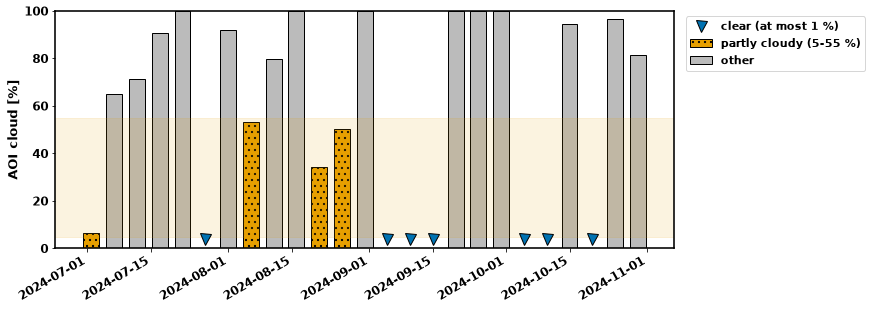

In [6]:
PARTLY_MIN, PARTLY_MAX, CLEAR_MAX = 5, 55, 1

def scene_class(c):
    return "clear" if c <= CLEAR_MAX else "partly cloudy" if PARTLY_MIN <= c <= PARTLY_MAX else "other"
scan["class"] = scan["AOI cloud %"].map(scene_class)

fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
for cls, color, hatch, text in [("partly cloudy", WONG[1], "..", f"partly cloudy ({PARTLY_MIN}-{PARTLY_MAX} %)"),
                                ("other", "#BBBBBB", "", "other")]:
    s = scan[scan["class"] == cls]
    ax.bar(pd.to_datetime(s["date"]), s["AOI cloud %"], width=3.5, color=color, hatch=hatch,
           edgecolor="black", linewidth=1.0, label=text)
s = scan[scan["class"] == "clear"]
ax.plot(pd.to_datetime(s["date"]), np.full(len(s), 4.0), linestyle="none", marker="v", markersize=11,
        color=WONG[5], markeredgecolor="black", label=f"clear (at most {CLEAR_MAX} %)")
ax.axhspan(PARTLY_MIN, PARTLY_MAX, color=WONG[1], alpha=0.12)
ax.set_ylabel("AOI cloud [%]"); ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.autofmt_xdate()
plt.show()

### 3.3 Select three scenes to mosaic and three candidates

**What this cell does.** It applies a simple, reproducible rule to the table:

- **to mosaic**: the three partly cloudy acquisitions with the least cloud in
  the AOI;
- **candidates**: the three clear acquisitions closest in time to the scenes
  to mosaic (smallest distance in days to their mean date). Close dates mean
  similar vegetation and water levels, which Step 4's similarity test (SSIM)
  needs.

It then gives each acquisition a file name in the pipeline's convention: the
scenes to mosaic become `a0000001`, `a0000003` and `a0000005`, the candidates
`a0000101`, `a0000103` and `a0000105`. Step 2 starts from the scene whose name
sorts first, so the scene to mosaic with the least cloud is named `a0000001`.

You can also pick dates by hand: set `mosaic` and `cands` to lists of rows of
`scan`.

In [7]:
partly = scan[scan["class"] == "partly cloudy"].sort_values("AOI cloud %")
mosaic = partly.head(3).copy()
mean_date = pd.to_datetime(mosaic["date"]).mean()
clear = scan[scan["class"] == "clear"].copy()
clear["days from mosaic dates"] = (pd.to_datetime(clear["date"]) - mean_date).dt.days.abs()
cands = clear.sort_values("days from mosaic dates").head(3).copy()

mosaic["name"] = ["a0000001", "a0000003", "a0000005"]
cands["name"] = ["a0000101", "a0000103", "a0000105"]
selection = pd.concat([mosaic.assign(role="mosaic"), cands.assign(role="candidate")])
selection[["name", "date", "item", "tile cloud %", "AOI cloud %", "role"]]

,name,date,item,tile cloud %,AOI cloud %,role
0,a0000001,2024-07-02,S2B_17TLE_20240702_0_L2A,17.6,6.6,mosaic
10,a0000003,2024-08-21,S2B_17TLE_20240821_1_L2A,25.7,34.4,mosaic
11,a0000005,2024-08-26,S2A_17TLE_20240826_0_L2A,25.6,50.2,mosaic
5,a0000101,2024-07-27,S2A_17TLE_20240727_0_L2A,0.0,0.0,candidate
13,a0000103,2024-09-05,S2A_17TLE_20240905_0_L2A,0.0,0.0,candidate
14,a0000105,2024-09-10,S2B_17TLE_20240910_0_L2A,7.9,0.0,candidate


## 4. Download with geoai-datacubes and convert to the pipeline's inputs

### 4.1 Imitating partly overlapping swaths

The pipeline mosaics scenes that **overlap only partly**, as neighbouring
satellite swaths do: Step 2 draws each seamline between the two points where the
boundaries of two overlapping scenes cross. Over Columbus every acquisition
covers the whole AOI (all come from Sentinel-2 tile 17TLE), so their outlines
would be identical. As in the walkthrough notebook, each scene to mosaic is
therefore cut to a tilted north-south strip (the angle comes from
`demo.TILT_DEG`, 8 degrees). Neighbouring strips overlap by about 2.5 km.

**What this cell does.** It defines the three strips (centre x and y, width and
height, in metres from the south-west corner of the AOI). The middle strip goes
to `a0000001`, the first scene in the processing order, so the mosaic grows
from the centre. With your own scenes from neighbouring swaths, you would skip
this and use the scenes as delivered.

In [8]:
STRIPS = {                             # name: (centre x, centre y, width, height) relative to the AOI corner
    "a0000003": (5_200, 10_000, 7_300, 16_500),     # west
    "a0000001": (10_000, 10_300, 7_300, 14_800),    # middle
    "a0000005": (14_800, 9_700, 7_300, 15_500),     # east
}
def strip_rect(name):
    sx, sy, w, h = STRIPS[name]
    return (AOI[0] + sx, AOI[1] + sy, w, h)

### 4.2 Download and convert each acquisition

**What this cell does.** For each of the six acquisitions it

1. downloads blue, green, red, near-infrared and the scene classification (SCL)
   at 20 m, and blue, green and red at 10 m, with geoai-datacubes'
   `fetch_sentinel_data`, onto the grids of section 2 (`grid=`). A one-day time
   window selects exactly the chosen acquisition; `max_cloud_coverage=1.0`
   turns off the download's own tile-level cloud filter, because the scenes
   were already chosen in section 3;
2. converts the 20 m bands to the pipeline's 12-bit XS scene (the values are
   surface reflectance x 10000; Earth Search has already removed the 1000
   offset of newer Sentinel-2 processing), the mean of the 10 m visible bands to
   a Pan scene, and the SCL to a cloud mask (classes 3, 8, 9 and 10, buffered
   by 200 m because the classification misses haze at cloud edges);
3. cuts the scenes to mosaic to their strips (section 4.1) and writes the files
   in the layout of the demo: `columbus_output/data/scenes/`, `candidates/`,
   `cloud_masks/` and `raw_pan/`, plus an all-land land/sea mask.

The downloads take about one minute. Each acquisition is downloaded only once;
the cell skips acquisitions whose files already exist.

In [9]:
TRUE_BITS = demo.TRUE_BITS          # 12
BUFFER_PX = demo.CLOUD_BUFFER_PX    # 10 pixels = 200 m

def to_12bit(a):
    a = np.nan_to_num(a, nan=0.0)
    dn = np.clip(np.round(a), 1, 2 ** TRUE_BITS - 1).astype(np.uint16)
    dn[a <= 0] = 0
    return dn

def crop(array, grid, bounds):
    """The part of an array on *grid* inside *bounds* (multiples of the pixel size)."""
    res = grid.transform.a
    c0, r0 = int(round((bounds[0] - AOI[0]) / res)), int(round((AOI[3] - bounds[3]) / res))
    c1, r1 = int(round((bounds[2] - AOI[0]) / res)), int(round((AOI[3] - bounds[1]) / res))
    return array[..., r0:r1, c0:c1]

def fetch(date, bands, grid, folder):
    day = pd.Timestamp(date)
    with contextlib.redirect_stdout(io.StringIO()):       # geoai-datacubes prints one line per band
        data, got = fetch_sentinel_data("Sentinel-2", bands, (str(day.date()), str((day + pd.Timedelta(days=1)).date())),
                                        aoi_fetch, resolution=grid.transform.a, save_folder=str(folder),
                                        max_cloud_coverage=1.0, provider="earthsearch", grid=grid)
    assert list(got) == bands, got
    return np.asarray(data[0])

def prepare(name, date, folder):
    if (DATA / folder / f"{name}.img").exists():
        return
    xs20 = fetch(date, ["B02", "B03", "B04", "B08", "SCL"], grid_xs, DATA / "downloads" / f"{name}_20m")
    vis10 = fetch(date, ["B02", "B03", "B04"], grid_pan, DATA / "downloads" / f"{name}_10m")
    if name in STRIPS:
        corners, bounds = demo.footprint(*strip_rect(name))
    else:
        corners, bounds = None, AOI
    xs = np.stack([to_12bit(b) for b in crop(xs20[:4], grid_xs, bounds)])
    scl = crop(xs20[4], grid_xs, bounds)
    valid = np.all(xs > 0, axis=0)
    if corners:
        valid &= demo.inside(corners, bounds, XS_RES)
    xs[:, ~valid] = 0
    demo.write(DATA / folder / f"{name}.img", xs, bounds, XS_RES, "HFA")
    cloud = binary_dilation(np.isin(scl, CLOUD_CLASSES), iterations=BUFFER_PX)
    demo.write(DATA / "cloud_masks" / f"{name}_cloud.tif", np.where(cloud & valid, 255, 0).astype(np.uint8),
               bounds, XS_RES, "GTiff")
    vis = [to_12bit(b) for b in crop(vis10, grid_pan, bounds)]
    pan = np.mean(vis, axis=0).astype(np.uint16)
    pan[np.any([v == 0 for v in vis], axis=0)] = 0
    if corners:
        pan[~demo.inside(corners, bounds, PAN_RES)] = 0
    demo.write(DATA / "raw_pan" / f"{demo.pan_name(name)}.tif", pan, bounds, PAN_RES, "GTiff")

# The demo functions write in the module's coordinate system and area: point them at ours.
demo.CRS, demo.AOI = CRS, AOI
for _, r in selection.iterrows():
    prepare(r["name"], r["date"], "scenes" if r["role"] == "mosaic" else "candidates")
    print(f"{r['name']}  {r['date']}  {r['role']:9s}  <- {r['item']}")
demo.write(DATA / "land_sea_mask.tif", np.ones((1000, 1000), np.uint8), AOI, XS_RES, "GTiff")

a0000001  2024-07-02  mosaic     <- S2B_17TLE_20240702_0_L2A
a0000003  2024-08-21  mosaic     <- S2B_17TLE_20240821_1_L2A
a0000005  2024-08-26  mosaic     <- S2A_17TLE_20240826_0_L2A
a0000101  2024-07-27  candidate  <- S2A_17TLE_20240727_0_L2A
a0000103  2024-09-05  candidate  <- S2A_17TLE_20240905_0_L2A
a0000105  2024-09-10  candidate  <- S2B_17TLE_20240910_0_L2A


### 4.3 Figure 2: the inputs

**What this cell does.** It draws the three strips to mosaic (a-c) and the three
candidates (d-f) in true colour, each with the outline of its cloud mask in
orange, all with the same contrast stretch, in UTM coordinates (km).

**What to look for.**

- The strips (a-c) have clouds in different places, and each overlaps its
  neighbour.
- The candidates (d-f) are clear over the whole AOI. Compare their colours with
  the strips: the closer the dates, the more alike the fields and trees look,
  and the more likely Step 4 accepts a candidate.

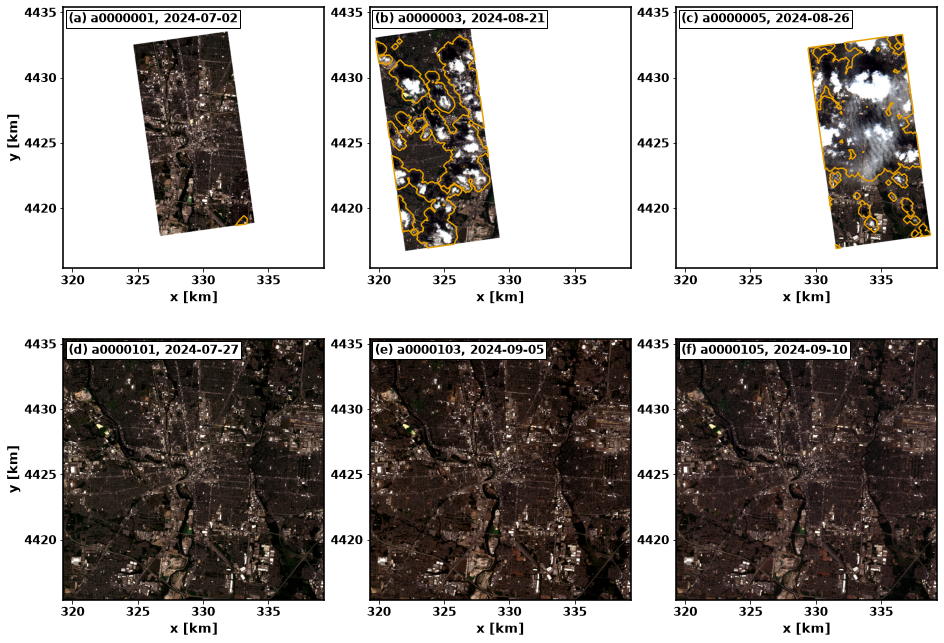

In [10]:
mosaic_names = list(mosaic["name"]); cand_names = list(cands["name"])
scene_files = [DATA / "scenes" / f"{n}.img" for n in mosaic_names]
cand_files = [DATA / "candidates" / f"{n}.img" for n in cand_names]
limits = stretch_limits(*scene_files)
aoi_km = [AOI[0] / 1000, AOI[2] / 1000, AOI[1] / 1000, AOI[3] / 1000]
dates = dict(zip(selection["name"], selection["date"]))

fig, axes = plt.subplots(2, 3, figsize=(13, 9.2), constrained_layout=True)
for k, (ax, f) in enumerate(zip(axes.flat, scene_files + cand_files)):
    name = f.stem
    show_rgb(ax, f, limits)
    outline(ax, DATA / "cloud_masks" / f"{name}_cloud.tif", lambda a: a > 0, WONG[1])
    map_axes(ax, aoi_km)
    label(ax, f"({'abcdef'[k]}) {name}, {dates[name]}")
for ax in axes[:, 0]:
    ax.set_ylabel("y [km]")
plt.show()

## 5. Run Steps 2-4

### 5.1 Step folders and parameter files

**What this cell does.** It tells the demo functions which scenes to use
(`demo.PRIMARY`, `demo.CANDIDATES`), then creates `columbus_output/step2/`,
`step3/` and `step4/` with their inputs and parameter files, exactly as in the
walkthrough notebook. Because `demo.CRS` and `demo.AOI` were set above, the
parameter files use UTM zone 17 N and the Columbus AOI. The Step 4 settings are
the same as in the demo: `cloud_tolerance` 0.25 and `ssim_threshold` 0.75.

In [11]:
demo.PRIMARY = [(n, "", None) for n in mosaic_names]
demo.CANDIDATES = [(n, "", None) for n in cand_names]
demo.set_up_steps(WORK, DATA)
demo.write_configs(WORK)
print((S2 / "para.txt").read_text().replace(str(WORK), "columbus_output"))

{
 "path_method": "a6c",
 "res": "20.0",
 "pan_res": "10.0",
 "resampleTo": "5",
 "trueBits": "12",
 "imgPath": "columbus_output/step2",
 "kernel": "11",
 "canvas_crs": "EPSG:32617",
 "canvas_x_max": "339300",
 "canvas_y_min": "4415400"
}


### 5.2 Run the three steps

**What this cell does.** It runs Step 2 (seamlines and the XS mosaic), copies
the Step 2 files that Step 3 needs and runs Step 3 (Pan mosaic), then copies the
mosaics into the Step 4 folder, keeps copies before filling (`*_raw.tif`) and
runs Step 4 (cloud filling), exactly as in the walkthrough notebook, where each
step is explained in detail. Each step runs as a separate process in its folder;
the cell prints the last lines of its output and, at the end, the share of the
cloudy area that was filled.

In [12]:
def run_step(script, folder):
    result = subprocess.run([sys.executable, str(REPO / script)], cwd=folder, capture_output=True, text=True)
    lines = [l for l in result.stdout.splitlines() if l.strip()]
    if result.returncode != 0:
        print("\n".join(lines[-40:]), result.stderr[-4000:])
        raise RuntimeError(f"{script} failed")
    print("\n".join(lines[-3:]))

run_step("step2_mosaic/step2mosaic.py", S2)
print("processing order:", (S2 / "ProcessOrder.txt").read_text(), "\n")
demo.copy_matching(S2, S3, ["transform.npy", "ImgInd.npy", "allWindow.npy", "Union_gt.npy",
                            "ProcessOrder.txt", "*_seamline_polygon.img", "*_seamline_polygon.img.aux.xml"])
run_step("step3_pan_mosaic/mosaicPan_block_rs.py", S3)
print()
demo.copy_matching(S2, S4, ["mosaic_xs.tif", "mosaic_cloudmask.tif", "allWindow.npy",
                            "transform.npy", "ProcessOrder.txt"])
demo.copy_matching(S3, S4, ["mosaic_pan.tif"])
for f in ("mosaic_xs.tif", "mosaic_pan.tif", "mosaic_cloudmask.tif"):
    shutil.copy(S4 / f, S4 / f.replace(".tif", "_raw.tif"))
run_step("step4_cloud_removal/step4cloud_removal.py", S4)

result = demo.check_results(S4)
print(f"\nCloudy area filled: {result['fill_fraction']:.0%}")

Writing cloud mask to disk...
All done!
Total time spent(hr): 0.0003536823841730236
processing order: ['a0000001.img', 'a0000005.img', 'a0000003.img'] 



Mosaicking and writing to disk...
All done!
Total time spent(hr): 8.513818278313717e-05



All done!
5 / 9  reconstructions of cloud-contaminated area
time(hr): 0.00028349513889730185

Cloudy area filled: 97%


## 6. Results

### 6.1 Figure 3: the mosaic before and after Step 4

**What this cell does.** Panel (a) draws the XS mosaic after Step 2 with the
seamlines (white with a black edge) and the outline of the clouds (orange).
Panel (b) draws the mosaic after Step 4 with the outline of the clouds left
unfilled. Panel (c) shows which cloud pixels were filled (blue) and which were
left (orange); grey is the rest of the mosaic.

**What to look for.**

- In (a), the seamlines run through the overlaps, around clouds and along roads
  and field edges.
- In (b), the filled areas should match their surroundings. Clouds that touch
  the edge of the mosaic are not filled (by design), nor are clouds for which no
  candidate is similar enough (SSIM below 0.75) or clear enough there.
- Where a filled area looks different from its surroundings, the candidate's
  date was probably too far from the mosaicked scene's: compare the dates in
  Figure 2, and try candidates closer in time.

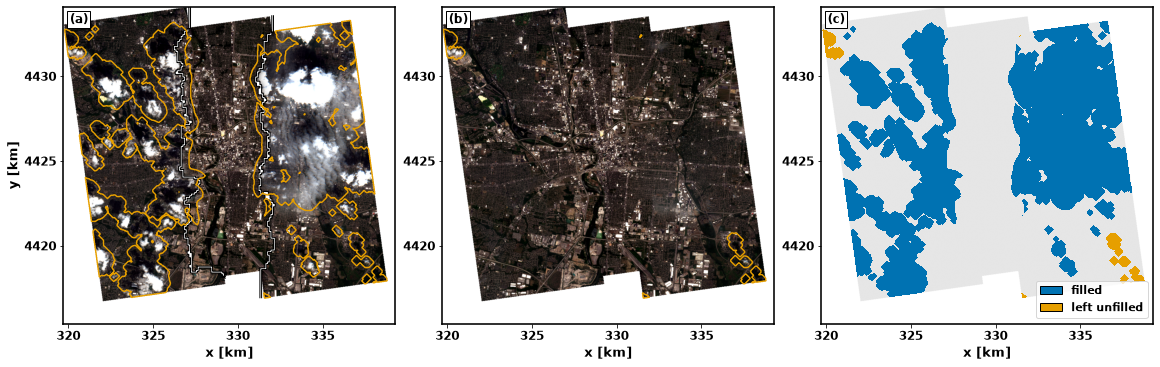

In [13]:
with rasterio.open(S4 / "mosaic_cloudmask_raw.tif") as src:
    before = src.read(1) == 1
    e = extent_km(src)
with rasterio.open(S4 / "mosaic_cloudmask.tif") as src:
    after = src.read(1) == 1
status = np.full(before.shape, np.nan)
status[before & ~after] = 0
status[after] = 1

fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), constrained_layout=True)
ax = axes[0]
show_rgb(ax, S4 / "mosaic_xs_raw.tif", limits)
for f in sorted(S2.glob("*_seamline.img")):
    with rasterio.open(f) as src:
        seam = src.read(1) == 1
        se = extent_km(src)
    ax.imshow(np.ma.masked_where(~seam, seam), extent=se, cmap=mpl.colors.ListedColormap(["white"]),
              interpolation="none")
    outline(ax, f, lambda a: a == 1, "black", "-", 1.0)
outline(ax, S4 / "mosaic_cloudmask_raw.tif", lambda a: a == 1, WONG[1])
map_axes(ax, e); ax.set_ylabel("y [km]"); label(ax, "(a)")
ax = axes[1]
show_rgb(ax, S4 / "mosaic_xs.tif", limits)
outline(ax, S4 / "mosaic_cloudmask.tif", lambda a: a == 1, WONG[1])
map_axes(ax, e); label(ax, "(b)")
ax = axes[2]
with rasterio.open(S4 / "mosaic_xs_raw.tif") as src:
    footprint = np.all(src.read() > 0, axis=0)
ax.imshow(np.where(footprint, 0.9, np.nan), extent=e, cmap="gray", vmin=0, vmax=1)
ax.imshow(status, extent=e, cmap=mpl.colors.ListedColormap([WONG[5], WONG[1]]), vmin=0, vmax=1,
          interpolation="none")
map_axes(ax, e); label(ax, "(c)")
ax.legend(handles=[Patch(facecolor=WONG[5], edgecolor="black", label="filled"),
                   Patch(facecolor=WONG[1], edgecolor="black", label="left unfilled")], loc="lower right")
plt.show()

### 6.2 Before/after slider

**What this cell does.** It shows the XS mosaic before and after Step 4 on top
of each other. Drag the slider: left of the white line is the mosaic before
Step 4, right of it the mosaic after. The slider needs the notebook to be
running (Colab, JupyterLab or Jupyter Notebook); a static view shows only the
first frame.


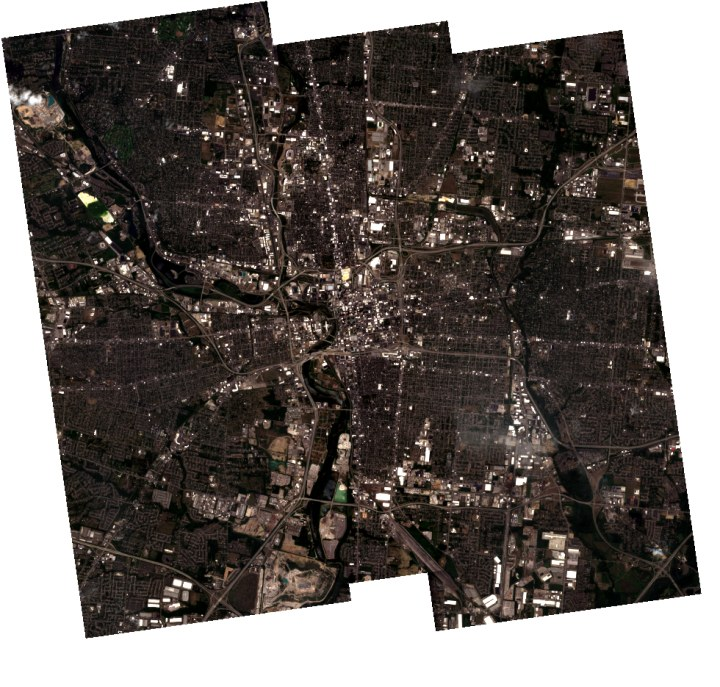
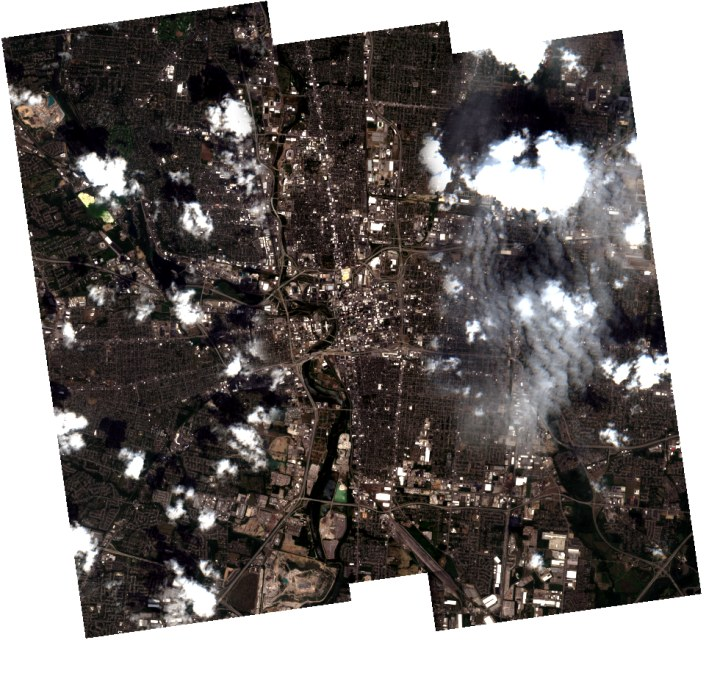

In [14]:
display(before_after_slider(S4 / "mosaic_xs_raw.tif", S4 / "mosaic_xs.tif", limits))

### 6.3 Which candidate filled each cloud

**What this cell does.** It reads Step 4's `fill_log.csv` (one row for each
candidate tried for each cloud patch; the columns are explained in the
walkthrough notebook) and counts, for each candidate, how many cloud patches it
filled and how many it was tried for.

**What to look for.** In the saved run, the 27 July candidate, the closest in
date to the mosaicked scenes, filled the most patches, and the 5 September
candidate filled none. A candidate that is never used is too different from the
mosaic around the clouds (SSIM below the threshold) or is itself cloudy there.

In [15]:
log = pd.read_csv(S4 / "fill_log.csv")
tried = log[log["candidate"].notna()]
summary = (tried.assign(filled=tried["filled"].eq("yes"))
                .groupby("candidate").agg(patches_tried=("patch", "size"), patches_filled=("filled", "sum")))
summary.index = [f"{c} ({dates[c[:-4]]})" for c in summary.index]
summary

,patches_tried,patches_filled
a0000101.img (2024-07-27),7,3
a0000103.img (2024-09-05),3,0
a0000105.img (2024-09-10),5,2


## 7. Adapting this to your own area

- **Area.** Change `CENTER` and `SIDE_MILES` in section 2, or pass a box or a
  shapefile to `resolve_aoi`. Keep the area small at first (20-30 km): Step 2
  builds a graph of every pixel in each overlap, and its run time grows with
  the overlap area.
- **Season.** Change `START` and `END` in section 3.1. Pick a period in which
  the land surface changes little, so that the candidates resemble the
  mosaicked scenes.
- **Scene selection.** Change `PARTLY_MIN`, `PARTLY_MAX` and `CLEAR_MAX`, or
  choose the rows of `scan` by hand in section 3.3.
- **Real swaths.** With scenes from neighbouring orbits that overlap only
  partly, skip the strips of section 4.1 and write the scenes as delivered.
- **Step 4 settings.** Edit `cloud_tolerance` and `ssim_threshold` in
  `columbus_output/step4/para_cld.txt` and rerun the Step 4 part of section 5.2.

The products are in `columbus_output/step4/` (`mosaic_xs.tif`, `mosaic_pan.tif`,
`mosaic_cloudmask.tif`). The [documentation website](https://buckai-observatory.org/Automated-Cloud-Removal-and-Seamless-Satellite-Image-Mosaicking-Pipeline/) describes every
input and parameter.